### Zadania

Celem listy jest zbadanie działania metod binaryzacji obrazów w skali szarości i kolorowych. Dążymy do wyobrębnienia obiektów znajdujących się na podanych obrazach, tzn. uzyskania separacji obiektów od tła, a także oddzielenia poszczególnych obiektów. Natomiast samo osiągnięcie "jakiegoś" wyniku ([`cv2.threshold`](https://docs.opencv.org/3.4/d7/d1b/group__imgproc__misc.html#gae8a4a146d1ca78c626a53577199e9c57) odpalone, próg wybrany "z palca", _coś tam_ wychodzi, wynik wyświetlony) to co najwyżej połowa sukcesu i oceny. Ważne jest przeprowadzenie eksperymentów wyjaśniających dobór parametrów.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

##### Zad. 1: Monety szare

Dane są dwa czarno-białe obrazy monet, `monety_szare` oraz `monety_szare_szum`, z których drugi zawiera pewien poziom zakłóceń. Dokonaj binaryzacji tych obrazów za pomocą progowania.  
Jak wartość progu wpływa na wyniki?  
Jaki wpływ mają zakłócenia w drugim obrazie? Zastosuj wybraną metodę odszumiania i przeanalizuj efekty.

In [2]:
monety_szare = cv2.imread('Monety_szare.bmp')
monety_szum = cv2.imread('Monety_szare_szum.bmp')

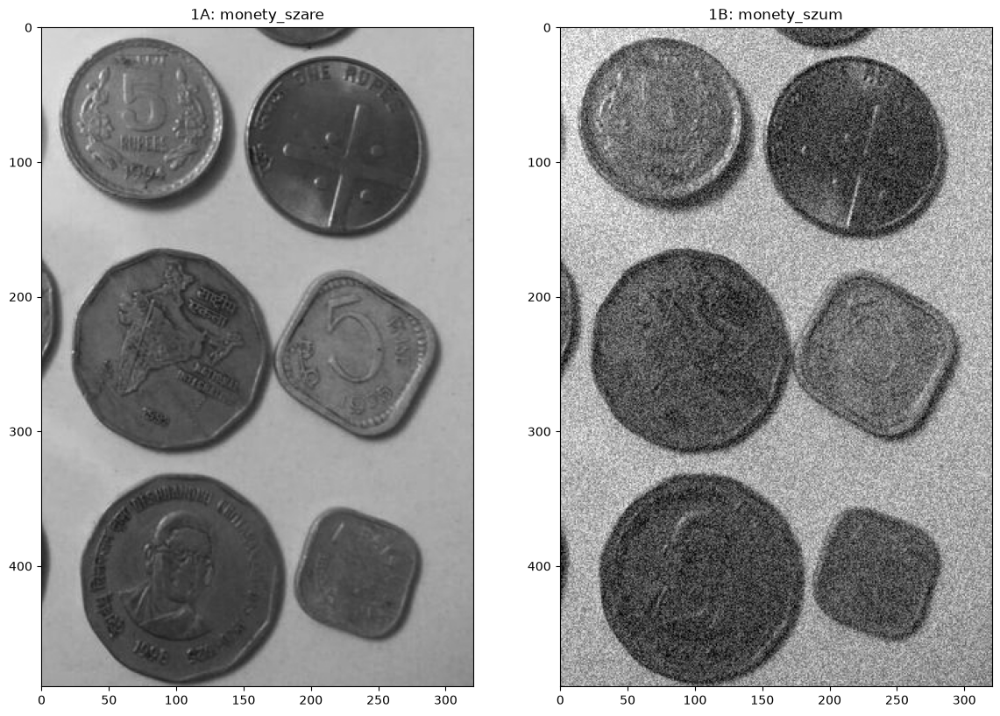

In [3]:
_, (a, b) = plt.subplots(1,2, figsize=(14,10))
a.imshow(monety_szare); a.title.set_text('1A: monety_szare')
b.imshow(monety_szum); b.title.set_text('1B: monety_szum')

Rozwiązanie części 1A:

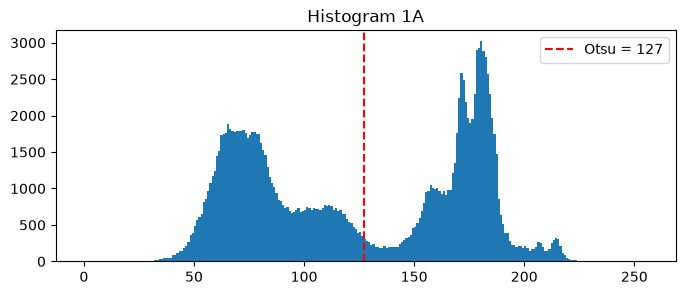

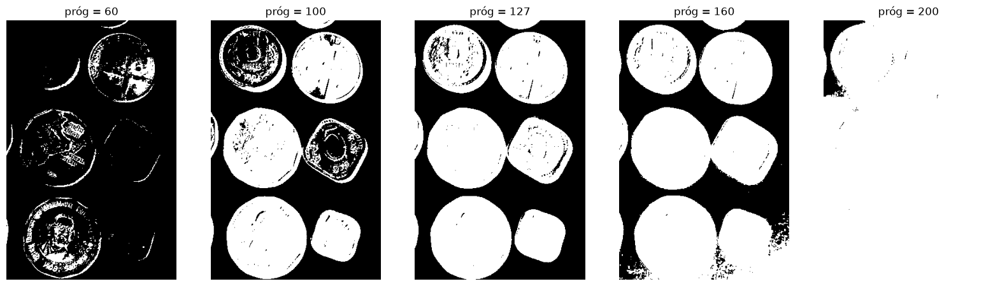

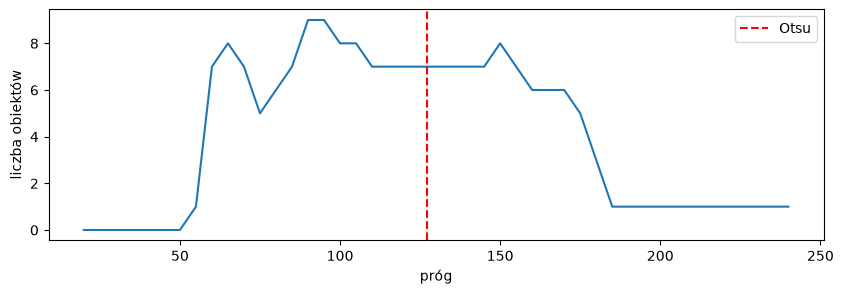

In [4]:
gray = cv2.cvtColor(monety_szare, cv2.COLOR_BGR2GRAY)

def count_objects(mask, min_area=500):
    """Liczba spójnych białych obszarów o polu >= min_area (mniejsze to artefakty)."""
    stats = cv2.connectedComponentsWithStats(mask)[2]
    return int((stats[1:, cv2.CC_STAT_AREA] >= min_area).sum())

t_otsu, mask_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
plt.figure(figsize=(8, 3)); plt.hist(gray.ravel(), 256, range=(0, 256))
plt.axvline(t_otsu, color='r', ls='--', label=f'Otsu = {t_otsu:.0f}'); plt.legend(); plt.title('Histogram 1A'); plt.show()

thresholds = [60, 100, 127, 160, 200]
_, axes = plt.subplots(1, len(thresholds), figsize=(20, 6))
for ax, t in zip(axes, thresholds):
    _, mask = cv2.threshold(gray, t, 255, cv2.THRESH_BINARY_INV)
    ax.imshow(mask, cmap='gray'); ax.set_title(f'próg = {t}'); ax.axis('off')
plt.show()

sweep = np.arange(20, 241, 5)
plt.figure(figsize=(10, 3))
plt.plot(sweep, [count_objects(cv2.threshold(gray, t, 255, cv2.THRESH_BINARY_INV)[1]) for t in sweep])
plt.axvline(t_otsu, color='r', ls='--', label='Otsu')
plt.xlabel('próg'); plt.ylabel('liczba obiektów'); plt.legend(); plt.show()

# Wnioski:
# - za niski próg (< 60): prawie nic nie jest obiektem, przy 60-100 monety są "dziurawe" i liczba obiektów skacze,
# - za wysoki próg (> 160): do obiektu wchodzi tło (cienie), monety się zlewają, przy > 180 wszystko to jeden obiekt,
# - dla progów 110-145 wynik jest stabilny (7 obiektów); Otsu (127) leży w dolinie histogramu, w środku tego przedziału,
# - 7 zamiast 8, bo duża i kwadratowa moneta stykają się - sam próg tego nie rozdzieli,
#   dopiero otwarcie morfologiczne 9x9 rozcina "mostek" między nimi (8 obiektów).

Rozwiązanie części 1B:


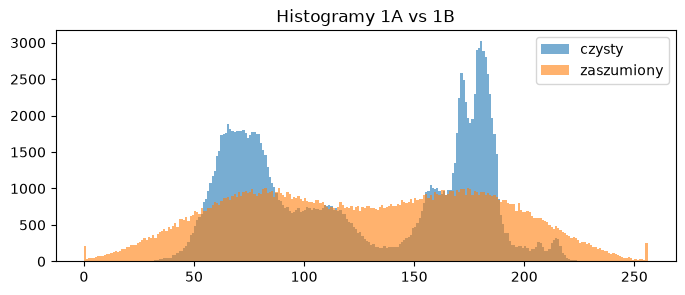

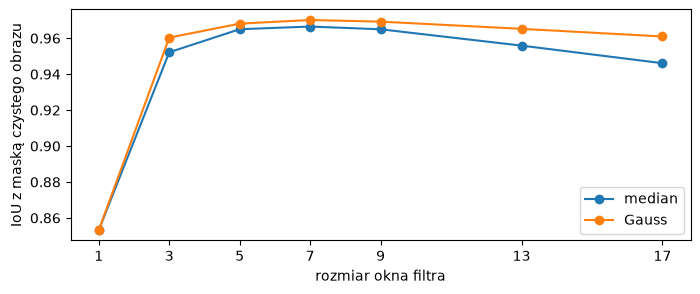

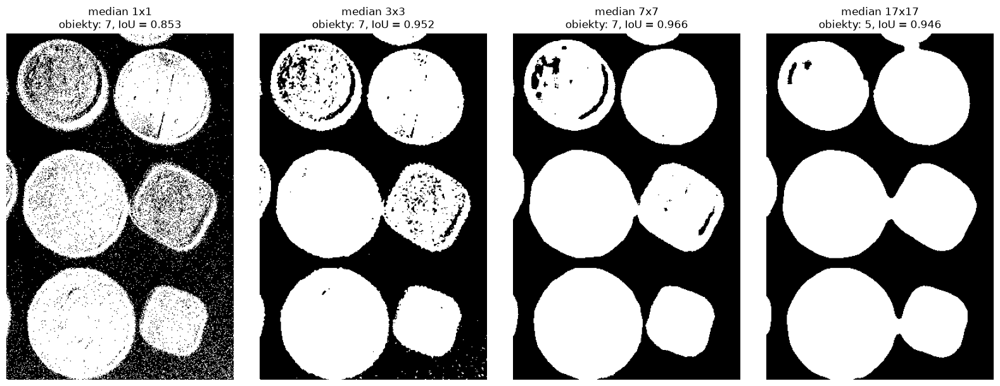

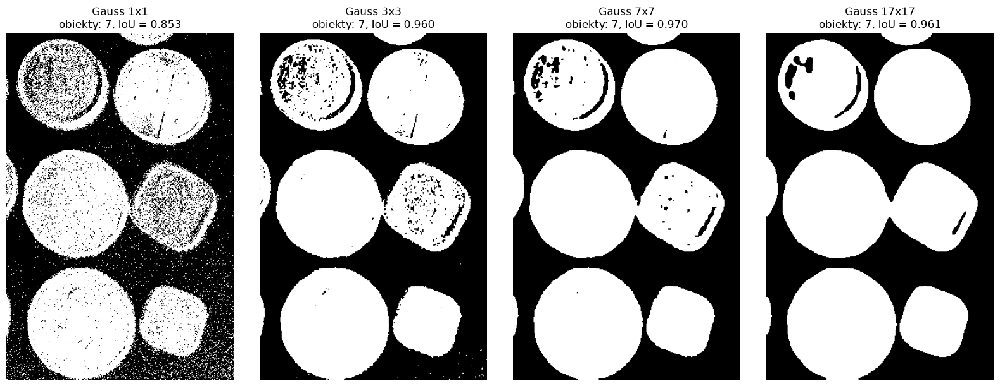

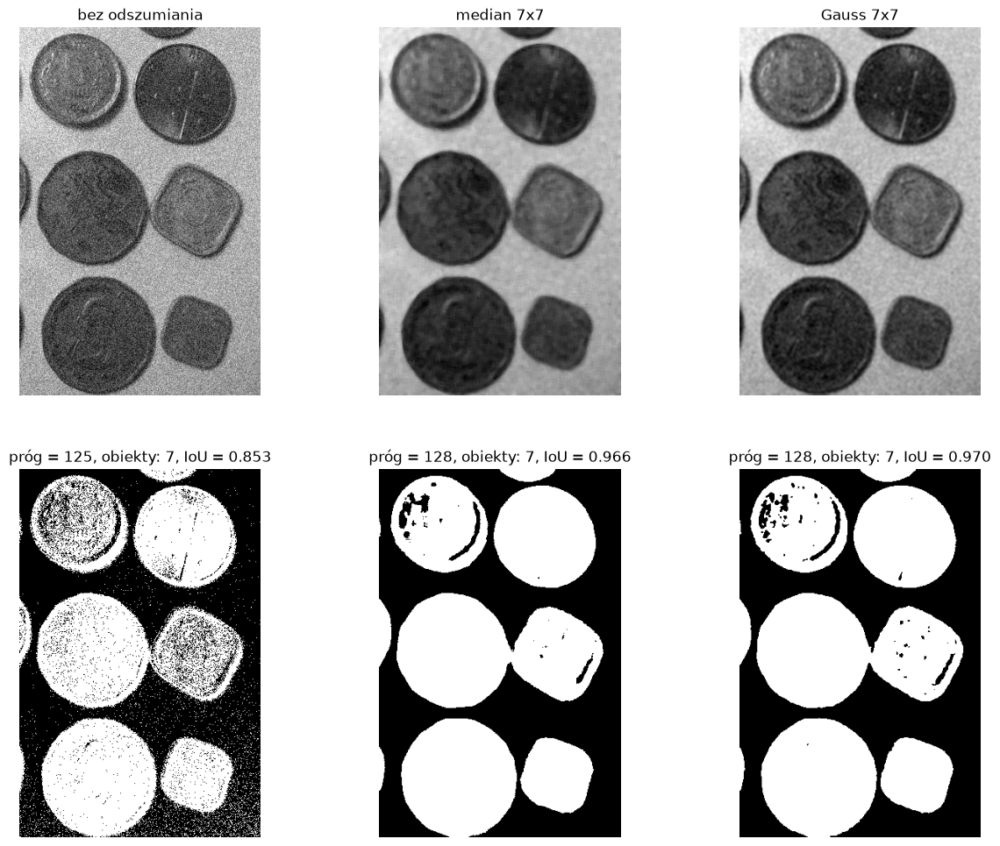

In [5]:
noisy = cv2.cvtColor(monety_szum, cv2.COLOR_BGR2GRAY)

def iou(a, b):
    a, b = a > 0, b > 0
    return (a & b).sum() / (a | b).sum()

def otsu_inv(img):
    return cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

plt.figure(figsize=(8, 3))
plt.hist(gray.ravel(), 256, range=(0, 256), alpha=0.6, label='czysty')
plt.hist(noisy.ravel(), 256, range=(0, 256), alpha=0.6, label='zaszumiony')
plt.legend(); plt.title('Histogramy 1A vs 1B'); plt.show()

kernel_sizes = [1, 3, 5, 7, 9, 13, 17]   # 1 = bez filtra
iou_median = [iou(otsu_inv(cv2.medianBlur(noisy, k))[1], mask_otsu) for k in kernel_sizes]
iou_gauss = [iou(otsu_inv(cv2.GaussianBlur(noisy, (k, k), 0))[1], mask_otsu) for k in kernel_sizes]
plt.figure(figsize=(8, 3))
plt.plot(kernel_sizes, iou_median, 'o-', label='median'); plt.plot(kernel_sizes, iou_gauss, 'o-', label='Gauss')
plt.xticks(kernel_sizes); plt.xlabel('rozmiar okna filtra'); plt.ylabel('IoU z maską czystego obrazu'); plt.legend(); plt.show()

filters = {
    'median': lambda img, k: cv2.medianBlur(img, k),
    'Gauss': lambda img, k: cv2.GaussianBlur(img, (k, k), 0),
}
shown_sizes = [1, 3, 7, 17]
for name, blur in filters.items():
    _, axes = plt.subplots(1, len(shown_sizes), figsize=(4 * len(shown_sizes), 6), constrained_layout=True)
    for ax, k in zip(axes, shown_sizes):
        t, mask = otsu_inv(blur(noisy, k))
        ax.imshow(mask, cmap='gray'); ax.set_title(f'{name} {k}x{k}\nobiekty: {count_objects(mask)}, IoU = {iou(mask, mask_otsu):.3f}'); ax.axis('off')
    plt.show()


variants = {
    'bez odszumiania': noisy,
    'median 7x7': cv2.medianBlur(noisy, 7),
    'Gauss 7x7': cv2.GaussianBlur(noisy, (7, 7), 0),
}
_, axes = plt.subplots(2, len(variants), figsize=(15, 12))
for i, (name, img) in enumerate(variants.items()):
    t, mask = otsu_inv(img)
    axes[0, i].imshow(img, cmap='gray'); axes[0, i].set_title(name); axes[0, i].axis('off')
    axes[1, i].imshow(mask, cmap='gray'); axes[1, i].set_title(f'próg = {t:.0f}, obiekty: {count_objects(mask)}, IoU = {iou(mask, mask_otsu):.3f}'); axes[1, i].axis('off')
plt.show()

# Wnioski:
# - szum rozmywa piki histogramu, przez co dowolny próg daje "pieprz i sól" w tle i dziury w monetach
#   (IoU z maską czystego obrazu tylko 0.853),
# - filtr przed progowaniem przywraca dwumodalny histogram i próg Otsu wraca do ~128 (jak dla obrazu czystego),
# - IoU rośnie do okna 7x7 (median 0.966, Gauss 0.970), a dla większych okien spada, bo rozmywają się
#   krawędzie monet i zaczynają się one sklejać (od 13x13 liczba obiektów spada z 7 do 5) - wybrane 7x7,
# - mediana lepiej zachowuje ostre krawędzie, Gauss daje gładsze wnętrza monet; różnica w IoU jest minimalna.

##### Zad. 2: Monety kolorowe

Na podobnej zasadzie dokonaj binaryzacji poniższego obrazu kolorowego.  
Skorzystaj z modelu barw HSV. Uzasadnij dobór kanału oraz progu binaryzacji.

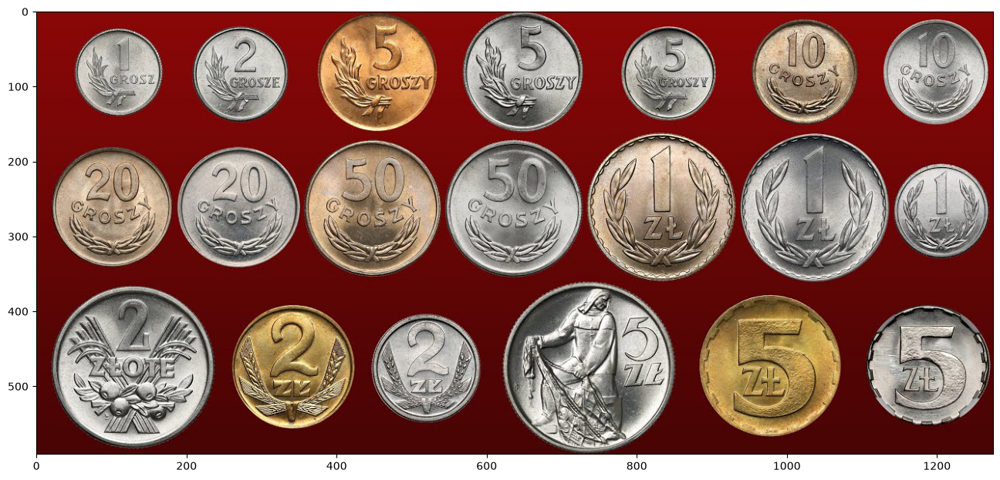

In [6]:
monety_kolor = cv2.imread('Monety_kolor.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor[..., ::-1]);

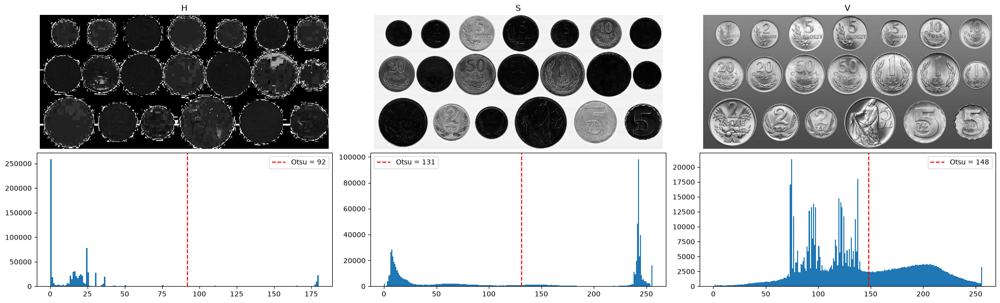

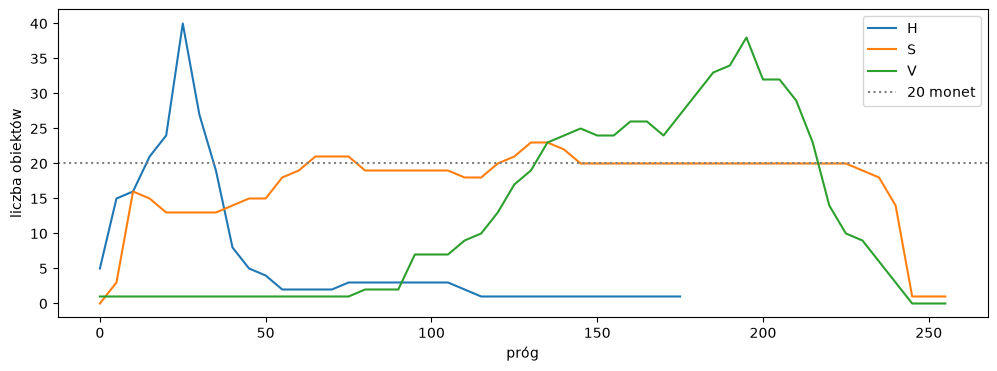

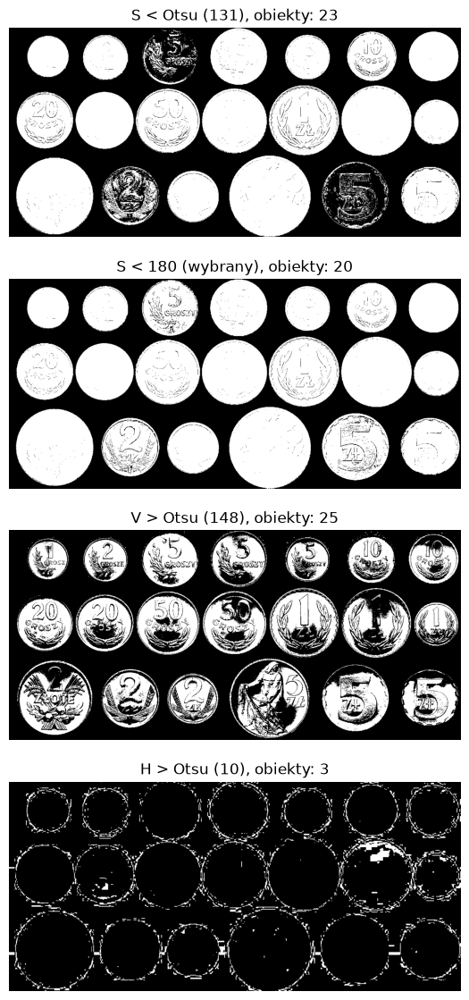

In [12]:
hsv = cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2HSV)
CHANNELS = ['H', 'S', 'V']

# kanały HSV (górny wiersz) i ich histogramy z progiem Otsu (dolny wiersz, skala log, bo pik tła dominuje)
_, axes = plt.subplots(2, 3, figsize=(20, 6), constrained_layout=True)
for i, name in enumerate(CHANNELS):
    t, _ = cv2.threshold(hsv[..., i], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    axes[0, i].imshow(hsv[..., i], cmap='gray'); axes[0, i].set_title(name); axes[0, i].axis('off')
    max_value = 180 if name == 'H' else 256   # H w OpenCV ma zakres 0-179
    axes[1, i].hist(hsv[..., i].ravel(), max_value, range=(0, max_value))
    axes[1, i].axvline(t, color='r', ls='--', label=f'Otsu = {t:.0f}'); axes[1, i].legend()
plt.show()

# dobór kanału: liczba obiektów w funkcji progu (H: H > T, S: S < T, V: V > T)
sweep = np.arange(0, 256, 5)
sweep_h = sweep[sweep < 180]   # H w OpenCV ma zakres 0-179
plt.figure(figsize=(12, 4))
plt.plot(sweep_h, [count_objects(cv2.threshold(hsv[..., 0], t, 255, cv2.THRESH_BINARY)[1]) for t in sweep_h], label='H')
plt.plot(sweep, [count_objects(cv2.threshold(hsv[..., 1], t, 255, cv2.THRESH_BINARY_INV)[1]) for t in sweep], label='S')
plt.plot(sweep, [count_objects(cv2.threshold(hsv[..., 2], t, 255, cv2.THRESH_BINARY)[1]) for t in sweep], label='V')
plt.axhline(20, color='gray', ls=':', label='20 monet')
plt.xlabel('próg'); plt.ylabel('liczba obiektów'); plt.legend(); plt.show()

# maski: Otsu na S, wybrany próg na S, Otsu na V
S_THRESHOLD = 180
t_s, mask_s_otsu = cv2.threshold(hsv[..., 1], 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
t_v, mask_v_otsu = cv2.threshold(hsv[..., 2], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
t_h, mask_h_otsu = cv2.threshold(hsv[..., 0], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
t_h = 10
_, mask_color = cv2.threshold(hsv[..., 1], S_THRESHOLD, 255, cv2.THRESH_BINARY_INV)
masks = [(f'S < Otsu ({t_s:.0f})', mask_s_otsu), (f'S < {S_THRESHOLD} (wybrany)', mask_color), (f'V > Otsu ({t_v:.0f})', mask_v_otsu), (f'H > Otsu ({t_h:.0f})', mask_h_otsu)]
_, axes = plt.subplots(4, 1, figsize=(12, 14))
for ax, (name, mask) in zip(axes, masks):
    ax.imshow(mask, cmap='gray'); ax.set_title(f'{name}, obiekty: {count_objects(mask)}'); ax.axis('off')
plt.show()

# Uzasadnienie:
# - H nie nadaje się: srebrne monety mają prawie zerowe nasycenie, więc ich odcień jest nieokreślony (szum),
#   a czerwone tło leży na H ~ 0 i ~179 (odcień się zawija) - liczba obiektów dla żadnego progu nie jest stabilna,
# - V nie nadaje się: tło ma gradient jasności, a monety refleksy - dla żadnego progu nie ma 20 obiektów,
# - S rozdziela najlepiej: tło jest silnie nasycone (~240), srebrne monety prawie wcale, złote/miedziane ~150,
# - liczba obiektów na S jest stabilna (20 monet) dla T = 145-225; próg Otsu (131) leży poniżej tego przedziału
#   i gubi części złotych monet, dlatego wybrany jest próg T = 180 ze środka przedziału.

Przetestuj opracowany powyżej algorytm na poniższym obrazie z wyraźnym zaszumieniem. Co się zmienia i dlaczego? Uzupełnij potok przetwarzania o odszumianie.

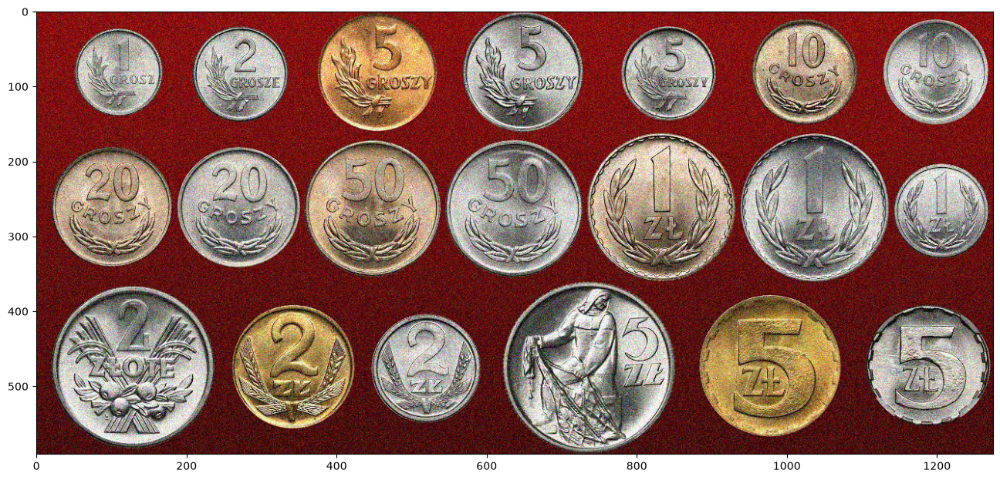

In [8]:
monety_kolor_szum = cv2.imread('Monety_kolor_szum.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor_szum[..., ::-1]);

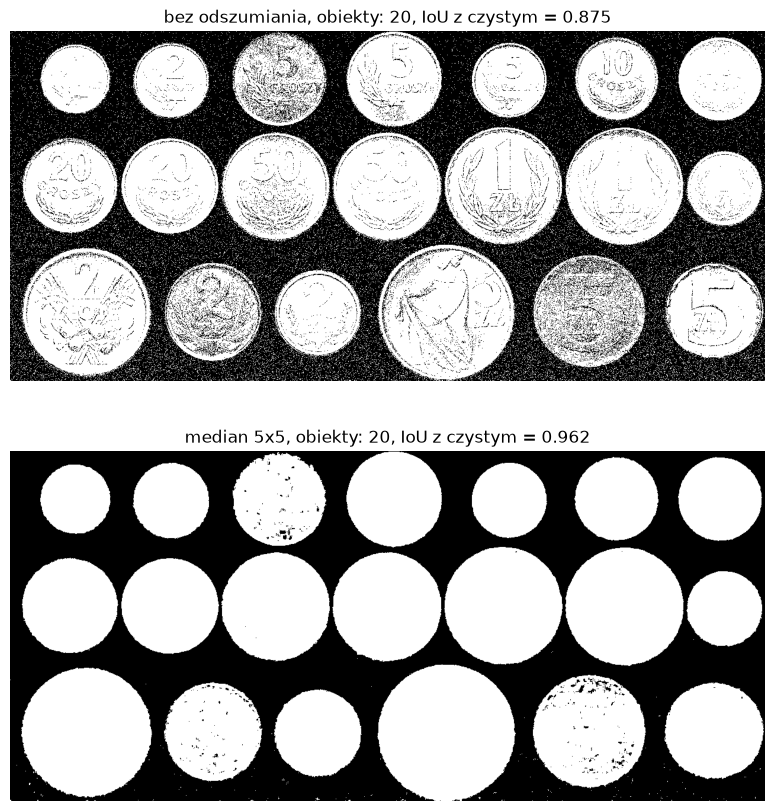

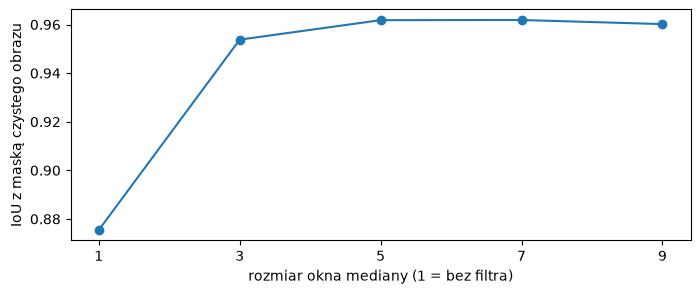

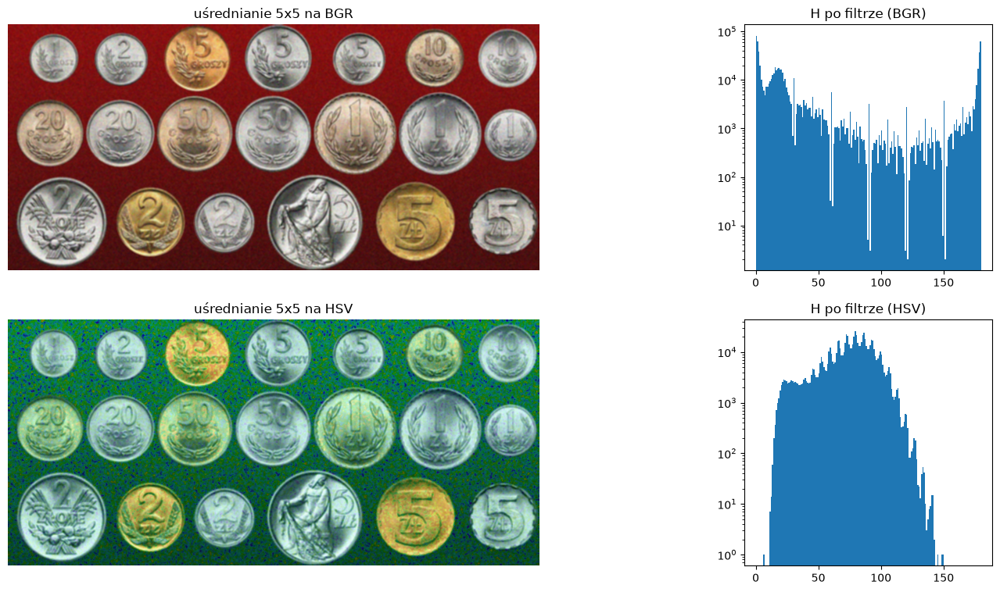

In [9]:
def binarize_color(img, threshold=S_THRESHOLD):
    s = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 1]
    return cv2.threshold(s, threshold, 255, cv2.THRESH_BINARY_INV)[1]

variants = {
    'bez odszumiania': monety_kolor_szum,
    'median 5x5': cv2.medianBlur(monety_kolor_szum, 5),
}
_, axes = plt.subplots(2, 1, figsize=(12, 10))
for ax, (name, img) in zip(axes, variants.items()):
    mask = binarize_color(img)
    ax.imshow(mask, cmap='gray'); ax.set_title(f'{name}, obiekty: {count_objects(mask)}, IoU z czystym = {iou(mask, mask_color):.3f}'); ax.axis('off')
plt.show()

# rozmiar okna mediany
kernel_sizes = [1, 3, 5, 7, 9]
plt.figure(figsize=(8, 3))
plt.plot(kernel_sizes, [iou(binarize_color(cv2.medianBlur(monety_kolor_szum, k)), mask_color) for k in kernel_sizes], 'o-')
plt.xticks(kernel_sizes); plt.xlabel('rozmiar okna mediany (1 = bez filtra)'); plt.ylabel('IoU z maską czystego obrazu'); plt.show()

# dlaczego nie odszumiać w HSV: H jest kątem (0-179 w OpenCV), czerwień leży jednocześnie przy 0 i przy 179
hsv_noisy = cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2HSV)

# ten sam filtr uśredniający 5x5: na BGR vs na kanałach HSV (wynik z powrotem do BGR, żeby zobaczyć barwy)
blur_bgr = cv2.blur(monety_kolor_szum, (5, 5))
blur_hsv = cv2.blur(hsv_noisy, (5, 5))
_, axes = plt.subplots(2, 2, figsize=(18, 9), gridspec_kw={'width_ratios': [3, 1]})
for row, (name, img, h) in enumerate([('uśrednianie 5x5 na BGR', blur_bgr, cv2.cvtColor(blur_bgr, cv2.COLOR_BGR2HSV)[..., 0]),
                                      ('uśrednianie 5x5 na HSV', cv2.cvtColor(blur_hsv, cv2.COLOR_HSV2BGR), blur_hsv[..., 0])]):
    axes[row, 0].imshow(img[..., ::-1]); axes[row, 0].set_title(name); axes[row, 0].axis('off')
    axes[row, 1].hist(h.ravel(), 180, range=(0, 180)); axes[row, 1].set_yscale('log'); axes[row, 1].set_title(f'H po filtrze ({name[-3:]})')
plt.show()


# Wnioski:
# - szum zmienia barwę pojedynczych pikseli: piksele tła o zaniżonym nasyceniu wpadają do maski, a w monetach
#   powstają dziury - IoU z maską czystego obrazu spada do 0.875; liczba monet nadal wynosi 20 tylko dzięki
#   odrzucaniu obiektów < 500 px, sama maska jest zaszumiona, a przedział stabilnych progów się zwęża (150-205),
# - filtr medianowy przed konwersją do HSV przywraca jednolite nasycenie tła: IoU ~0.962 dla 5x5
#   (7x7 daje to samo, 9x9 już mniej, bo rozmywa krawędzie monet), więc wybrane jest 5x5,
# - odszumianie trzeba robić na BGR, nie na HSV: H jest kątem, a szum rozrzuca czerwone tło po obu końcach skali
#   (H ~ 0-10 i H ~ 170-179); filtr uśredniający liczy zwykłą średnią, np. (0 + 178) / 2 = 89 (ok. 178°, cyjan),
#   więc czerwone tło po filtrze na HSV staje się zielono-turkusowe - zmieniamy barwę, zamiast usuwać szum
#   (S i V się nie zawijają, ale H już tak).

##### Zad. 3: Tekst

W tym przypadku należy wyodrębnić litery od bardzo nierównomiernie oświetlonego tła. Skorzystaj z binaryzacji metodą Otsu. Zastosuj binaryzację w sposób lokalny (oknem przesuwnym). Jaki wpływ ma rozmiar okna na jakość binaryzacji? Jak przesuwać okno?

_(Pełna punktacja za zadanie wymaga własnoręcznej implementacji okna przesuwnego - samo Otsu możesz wziąć z OpenCV. Użycie zamiast tego_ `cv2.adaptiveThreshold` _liczone będzie jako pół zadania, ale jedynie po demonstracji zrozumienia tej metody.)_

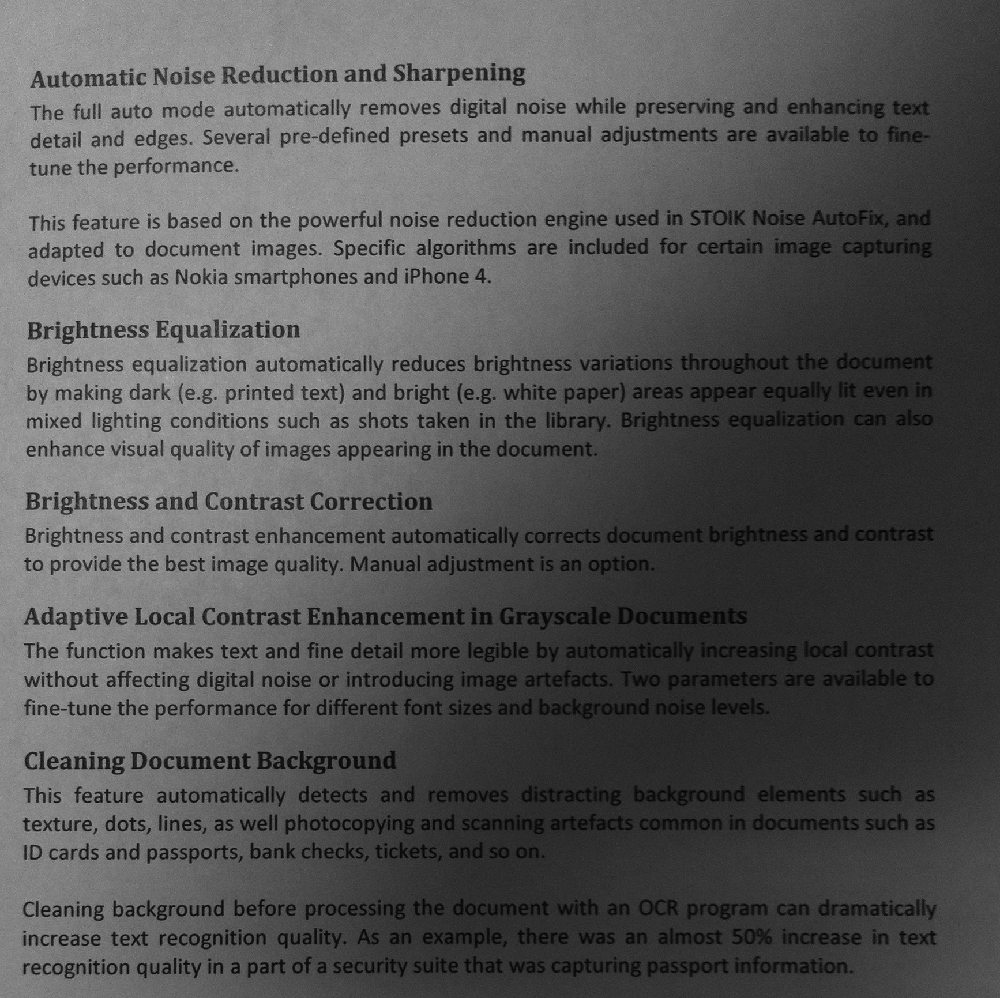

In [10]:
tekst = cv2.imread('Tekst1.bmp')
Image.fromarray(cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY))

Rozwiązanie:

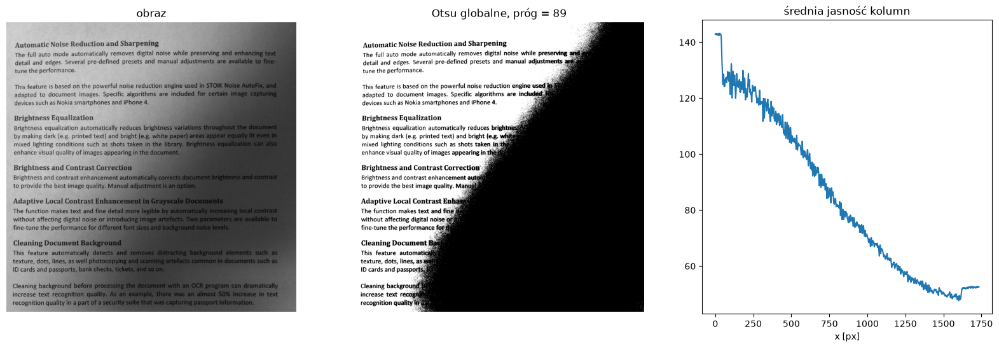

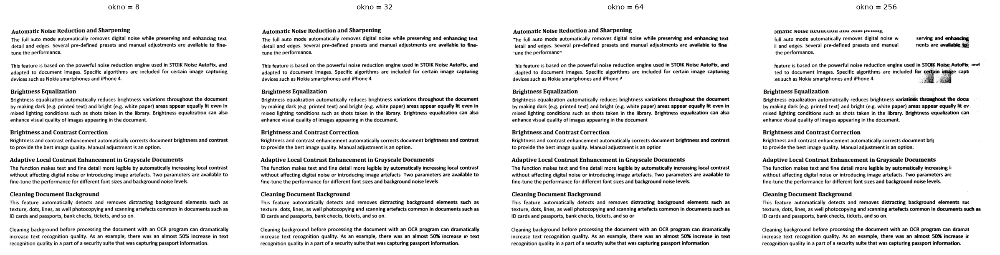

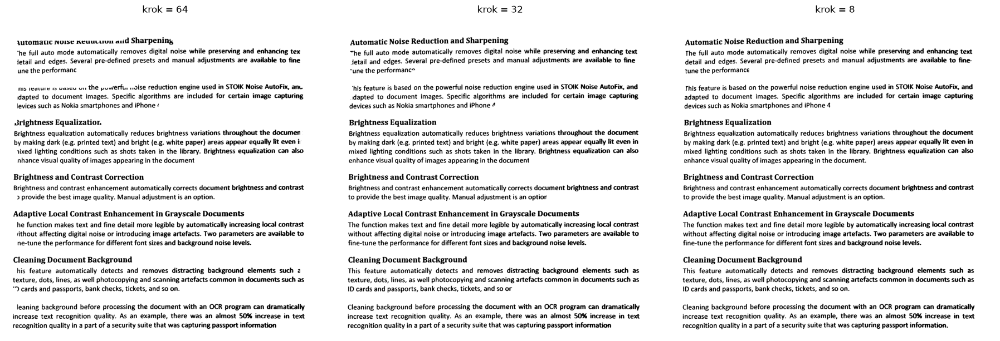

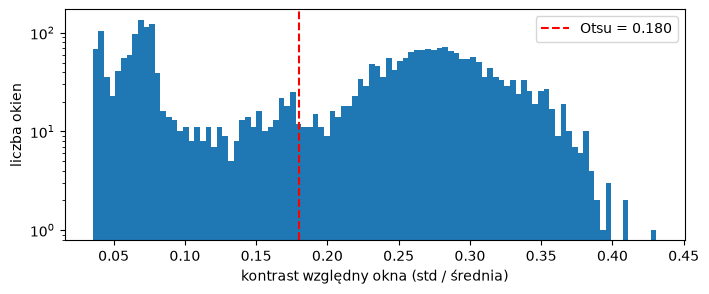

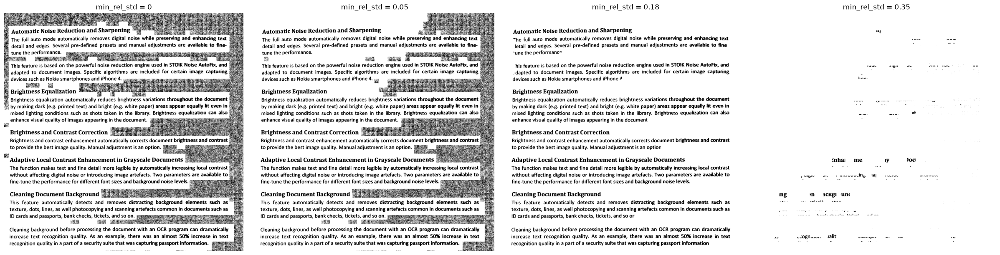

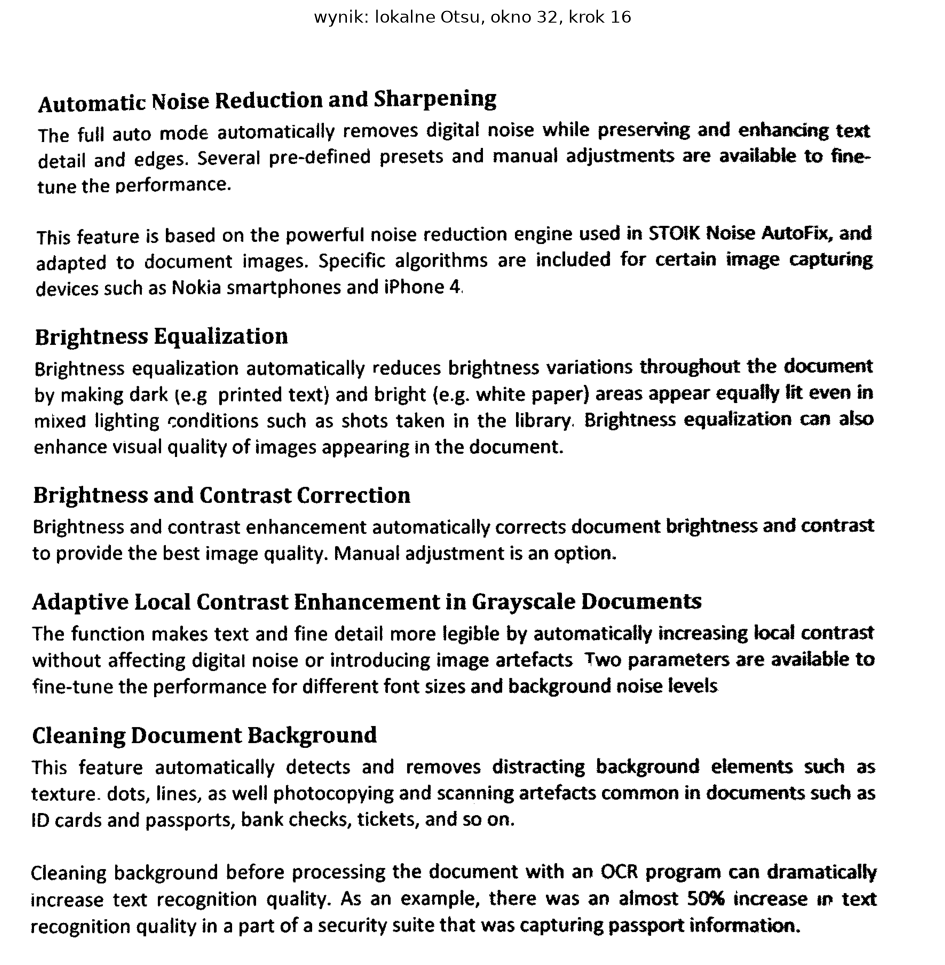

In [11]:
from skimage.filters import threshold_otsu

text_gray = cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY)

def window_contrasts(img, window, step):
    """Kontrast względny (std / średnia) każdego okna - tych samych okien, które przegląda local_otsu."""
    h, w = img.shape
    m = (window - step) // 2
    padded = cv2.copyMakeBorder(img, m, m + window, m, m + window, cv2.BORDER_REFLECT)
    contrasts = []
    for y in range(0, h, step):
        for x in range(0, w, step):
            patch = padded[y:y + window, x:x + window]
            contrasts.append(patch.std() / max(patch.mean(), 1))
    return np.array(contrasts)

def local_otsu(img, window, step, min_rel_std=None):
    """Otsu w oknie przesuwnym: próg liczony w każdym oknie i stosowany do jego środkowej części (step x step)."""
    # okna o kontraście < min_rel_std to samo tło - Otsu wymyśliłby w nich sztuczny podział;
    # domyślnie granicę wyznacza Otsu na rozkładzie kontrastów okien (klasy: samo tło / tekst)
    if min_rel_std is None:
        min_rel_std = threshold_otsu(window_contrasts(img, window, step))
    h, w = img.shape
    result = np.zeros_like(img)
    m = (window - step) // 2                    # margines: okno jest szersze od obszaru, któremu nadaje próg
    padded = cv2.copyMakeBorder(img, m, m + window, m, m + window, cv2.BORDER_REFLECT)
    for y in range(0, h, step):
        for x in range(0, w, step):
            patch = padded[y:y + window, x:x + window]
            # kontrast względny, bo skaluje się z oświetleniem (po ciemnej stronie litery mają mały kontrast bezwzględny)
            if patch.std() < min_rel_std * patch.mean():
                t = 0
            else:
                t, _ = cv2.threshold(patch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            center = img[y:y + step, x:x + step]
            result[y:y + step, x:x + step] = np.where(center > t, 255, 0)
    return result

# globalne Otsu i profil oświetlenia
t_global, mask_global = cv2.threshold(text_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].imshow(text_gray, cmap='gray'); axes[0].set_title('obraz'); axes[0].axis('off')
axes[1].imshow(mask_global, cmap='gray'); axes[1].set_title(f'Otsu globalne, próg = {t_global:.0f}'); axes[1].axis('off')
axes[2].plot(text_gray.mean(axis=0)); axes[2].set_title('średnia jasność kolumn'); axes[2].set_xlabel('x [px]')
plt.show()

def show_param(param, values, make_mask):
    """Jeden parametr w jednym wierszu: wynik dla kilku jego wartości obok siebie."""
    _, axes = plt.subplots(1, len(values), figsize=(6 * len(values), 6), constrained_layout=True)
    for ax, value in zip(axes, values):
        ax.imshow(make_mask(value), cmap='gray'); ax.set_title(f'{param} = {value}'); ax.axis('off')
    plt.show()

# wpływ rozmiaru okna (krok = połowa okna, czyli okna nachodzą na siebie)
show_param('okno', [8, 32, 64, 256], lambda window: local_otsu(text_gray, window, window // 2))

# jak przesuwać okno: kafelki (krok = okno) vs okna nachodzące na siebie (okno 64)
show_param('krok', [64, 32, 8], lambda step: local_otsu(text_gray, 64, step))

# reguła minimalnego kontrastu: rozkład kontrastów okien i granica wyznaczona przez Otsu
contrasts = window_contrasts(text_gray, 64, 32)
min_rel_std = threshold_otsu(contrasts)
plt.figure(figsize=(8, 3)); plt.hist(contrasts, 100); plt.yscale('log')
plt.axvline(min_rel_std, color='r', ls='--', label=f'Otsu = {min_rel_std:.3f}')
plt.xlabel('kontrast względny okna (std / średnia)'); plt.ylabel('liczba okien'); plt.legend(); plt.show()

# wpływ granicy kontrastu (okno 64, krok 32): bez reguły, za niska, z Otsu, za wysoka
show_param('min_rel_std', [0, 0.05, round(min_rel_std, 3), 0.35], lambda r: local_otsu(text_gray, 64, 32, r))

mask_text = local_otsu(text_gray, 32, 16)
plt.figure(figsize=(12, 12)); plt.imshow(mask_text, cmap='gray'); plt.title('wynik: lokalne Otsu, okno 32, krok 16'); plt.axis('off'); plt.show()

# Wnioski:
# - globalny próg zawodzi: jasność tła spada od ~140 (lewa strona) do ~50 (prawa), jeden próg nie pasuje do obu,
# - okno bez tekstu: Otsu zawsze coś podzieli, więc bez reguły kontrastu całe tło zamienia się w szum;
#   kontrast musi być względny (std / średnia), bo po ciemnej stronie litery mają mały kontrast bezwzględny,
# - granicy kontrastu nie ustawiamy ręcznie: rozkład kontrastów okien jest dwumodalny (okna z samym tłem i okna
#   z tekstem), więc wyznacza ją Otsu na tym rozkładzie (~0.18-0.25 zależnie od rozmiaru okna),
#   za niska granica (0.05) zostawia szum w tle, za wysoka (0.35) usuwa tekst,
# - małe okno (8-32): wynik poprawny na całej stronie, przy 8 litery są minimalnie "nadgryzione", bo okno widzi tylko kreski,
# - okno 64: na marginesach okna zawierają głównie tło, więc skrajne litery (początki/końce linii) bywają ucinane,
# - za duże okno (256): oświetlenie w oknie znów jest nierówne - po ciemnej stronie znika tekst i pojawiają się łaty
#   szumu (powrót problemów progu globalnego),
# - dobre okno (ok. 32) to 1-2 wysokości litery - zawiera i litery, i tło, a oświetlenie w nim jest prawie stałe,
# - okno przesuwamy z krokiem mniejszym niż jego rozmiar (nakładanie się), a próg stosujemy tylko do środka okna;
#   przy krok = okno (kafelki) litery na granicach kafelków są ucinane, mniejszy krok to usuwa kosztem czasu obliczeń.